<a href="https://colab.research.google.com/github/erestrepol/Business-Intelligence/blob/main/Proyecto_Final_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modelo Naive Bayes**

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
nxl='/content/Diabetes Base de Datos.xlsx'
XDB=pd.read_excel(nxl, sheet_name=0) #Base de datos triple A
XDB=XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age','Outcome']]
display(XDB)

#Separamos las variables por entrada y salida
XD=np.array(XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']])
yd=np.array(XDB[['Outcome']])

,Pregnancies,Glucosa,Blood Pressure,Skin Thickness,Insulin,BMI,Diabetes Pedigree Function,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


Para la predicción de personas que pueden padecer diabetes tipo 2, se consideraron 8 variables de entrada relacionadas con factores clínicos, fisiológicos y hereditarios, y una de salida que indica si la persona tiene o no diabetes.

**Variables de Entrada**

 - **Pregnancies** (Número de embarazos):
Representa cuántas veces ha estado embarazada la persona (generalmente mujeres). Un mayor número de embarazos puede estar relacionado con un aumento del riesgo de diabetes gestacional, que a su vez puede derivar en diabetes tipo 2 en el futuro.

- **Glucose** (Nivel de glucosa en sangre):
Es la concentración de glucosa en sangre en ayunas. Valores elevados son un fuerte indicador de diabetes, ya que reflejan que el cuerpo no está procesando bien el azúcar.

- **Blood Pressure** (Presión arterial diastólica):
Corresponde a la presión que ejerce la sangre contra las paredes de las arterias cuando el corazón está en reposo. La presión alta es un factor de riesgo común en personas con diabetes.

- **Skin Thickness** (Espesor del pliegue cutáneo):
Mide el grosor de la piel en el área del tríceps. Este valor está asociado a la cantidad de grasa corporal; niveles altos pueden indicar sobrepeso, un factor de riesgo importante para la diabetes tipo 2.

- **Insulin** (Nivel de insulina):
Indica la cantidad de insulina en sangre. La insulina es la hormona que regula los niveles de glucosa. Niveles anormales pueden evidenciar resistencia a la insulina, una característica central en la diabetes tipo 2.

- **BMI** (Índice de Masa Corporal):
Es la relación entre el peso y la altura de la persona. Un BMI elevado refleja sobrepeso u obesidad, condiciones altamente asociadas al desarrollo de diabetes.

- **Diabetes Pedigree Function** (Historial familiar de diabetes):
Evalúa la probabilidad de que una persona desarrolle diabetes en función de antecedentes familiares. Valores altos indican una mayor predisposición genética a la enfermedad.

- **Age** (Edad):
Es la edad de la persona. A medida que aumenta la edad, también lo hace el riesgo de desarrollar diabetes, especialmente a partir de los 45 años.

**Varaibles de Salida**

- **Outcome** (Resultado del diagnóstico):
Es la variable objetivo, es decir, la que se quiere predecir. Esta variable es categórica y toma dos posibles valores:

 **0: No tiene diabetes.**

 **1: Tiene diabetes.**

In [ ]:
total_datos1 = len(XDB)
print(f"Número total de datos: {total_datos1}")

porcentaje_por_variable1 = (XDB.count() / total_datos1) * 100
print("\nPorcentaje de datos por variable:")
print(porcentaje_por_variable1)

# Contar el número de personas con diabetes (Outcome == 1)
num_diabetes = XDB[XDB['Outcome'] == 1].shape[0]

# Contar el número de personas sin diabetes (Outcome == 0)
num_sindiabetes = XDB[XDB['Outcome'] == 0].shape[0]

print(f"Número de diagnósticos con diabetes (1): {num_diabetes}")
print(f"Número de diagnósticos sin diabetes (0): {num_sindiabetes}")

Número total de datos: 769

Porcentaje de datos por variable:
Pregnancies                   100.0
Glucosa                       100.0
Blood Pressure                100.0
Skin Thickness                100.0
Insulin                       100.0
BMI                           100.0
Diabetes Pedigree Function    100.0
Age                           100.0
Outcome                       100.0
dtype: float64
Número de diagnósticos con diabetes (1): 269
Número de diagnósticos sin diabetes (0): 500


In [ ]:
from sklearn.naive_bayes import GaussianNB
import numpy as np

XD1=XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']] #Variables de entrada
yd=XDB[['Outcome']] #Variable pronóstico

mnb=GaussianNB()
mnb.fit(XD1,yd)


#Obtenemos la información del modelo
u=mnb.theta_ #Obtenemos la media
print("la media de las variables es: \n", u)

var=mnb.var_ #Se calculan las varianzas, me indica que tan alejados están los datos de la media
sigma=np.sqrt(var) #Se calcula la desviación
print("La desviación de las variables es: \n", sigma)

#Se determinan los límites superiores e inferiores de las tres variables
LS=u+sigma
LI=u-sigma

print("El limite superior de las variables es \n", LS)
print("El limite inferior de las variables es \n", LI)
yd=XDB[['Outcome']] #Variable pronóstico

mnb=GaussianNB()
mnb.fit(XD,yd)


#Obtenemos la información del modelo
u=mnb.theta_ #Obtenemos la media
print("la media de las variables es: \n", u)

var=mnb.var_ #Se calculan las varianzas, me indica que tan alejados están los datos de la media
sigma=np.sqrt(var) #Se calcula la desviación
print("La desviación de las variables es: \n", sigma)

#Se determinan los límites superiores e inferiores de las tres variables
LS=u+sigma
LI=u-sigma

print("El limite superior de las variables es \n", LS)
print("El limite inferior de las variables es \n", LI)

la media de las variables es: 
 [[  3.298      109.98        68.184       19.664       68.792
   30.3042       0.429734    31.19      ]
 [  4.84758364 141.18959108  70.84758364  22.08178439  99.96654275
   35.14684015   0.54939033  37.133829  ]]
La desviación de las variables es: 
 [[  3.01416809  26.11504573  18.04500366  14.87505016  98.76637459
    7.68216217   0.29880825  11.65598187]
 [  3.73905068  31.84005885  21.41506562  17.66543727 138.30477501
    7.23626076   0.37143005  10.98176686]]
El limite superior de las variables es 
 [[  6.31216809 136.09504573  86.22900366  34.53905016 167.55837459
   37.98636217   0.72854225  42.84598187]
 [  8.58663432 173.02964992  92.26264926  39.74722166 238.27131776
   42.38310091   0.92082038  48.11559586]]
El limite inferior de las variables es 
 [[  0.28383191  83.86495427  50.13899634   4.78894984 -29.97437459
   22.62203783   0.13092575  19.53401813]
 [  1.10853296 109.34953223  49.43251803   4.41634711 -38.33823226
   27.91057939   0.17

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


3. Evaluar a un solicitante

In [ ]:
#Evaluar un registro
from sklearn.naive_bayes import GaussianNB

mnb=GaussianNB() #Aloja el modelo
mnb.fit(XD,yd) #Entrena el modelo

XDS=[[7, 189, 80, 30, 0, 26.6, 0.13, 50]]
ydp=mnb.predict(XDS) #Se obtiene la predicción
print("La predicción del registro es:\n", ydp)

if ydp=="CD":
  print("El registro forma parte de los diagnósticos con diabetes")

if ydp=="SD":
  print("El registro forma parte de los diagnósticos sin diabetes")

La predicción del registro es:
 [1]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


4. Se evalua el desempeño del modelo

In [ ]:
from sklearn.metrics import confusion_matrix

#Haga un barrido de los datos
ydp2=mnb.predict(XD) #Haga el pronóstico para los datos base

cm=confusion_matrix(yd,ydp2)
print("La matriz de confusión es: \n", cm)
VN=cm[0,0]
FP=cm[0,1]
FN=cm[1,0]
VP=cm[1,1]

#Métricas de desempeño
Ex=(VP+VN)/(VP+VN+FP+FN) #Exactitud: Comportamiento general preaprobando
print("La exactitud del modelo es: \n", Ex)

TE=(FN+FP)/(VP+VN+FP+FN) #Tasa de error: Comportamiento general no preaprobando
print("La tasa de error del modelo es: \n", TE)

Se=VP/(VP+FN) #Sensibilidad: Comportamiento correcto preaprobando
print("La sensibilidad del modelo es: \n", Se)

Sp=VN/(VN+FP) #Especificidad: Comportamiento correcto no preaprobando
print("La especificidad del modelo es: \n", Sp)

Pr=VP/(VP+FP) #Precisión: Comportamiento correcto preaprobando
print("La precisión del modelo es: \n", Pr)

PrNeg=VN/(VN+FN) #Precisión negativa: Comportamiento correcto no preaprobando
print("La precisión negativa del modelo es: \n", PrNeg)

La matriz de confusión es: 
 [[421  79]
 [103 166]]
La exactitud del modelo es: 
 0.7633289986996099
La tasa de error del modelo es: 
 0.23667100130039012
La sensibilidad del modelo es: 
 0.6171003717472119
La especificidad del modelo es: 
 0.842
La precisión del modelo es: 
 0.6775510204081633
La precisión negativa del modelo es: 
 0.8034351145038168


# **Modelo Clusterización**

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
nxl='/content/Diabetes Base de Datos.xlsx'
XDB=pd.read_excel(nxl, sheet_name=0) #Base de datos triple A
XDB=XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age','Outcome']]
display(XDB)

#Separamos las variables por entrada y salida
XD=np.array(XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']])
yd=np.array(XDB[['Outcome']])

,Pregnancies,Glucosa,Blood Pressure,Skin Thickness,Insulin,BMI,Diabetes Pedigree Function,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 640x480 with 0 Axes>

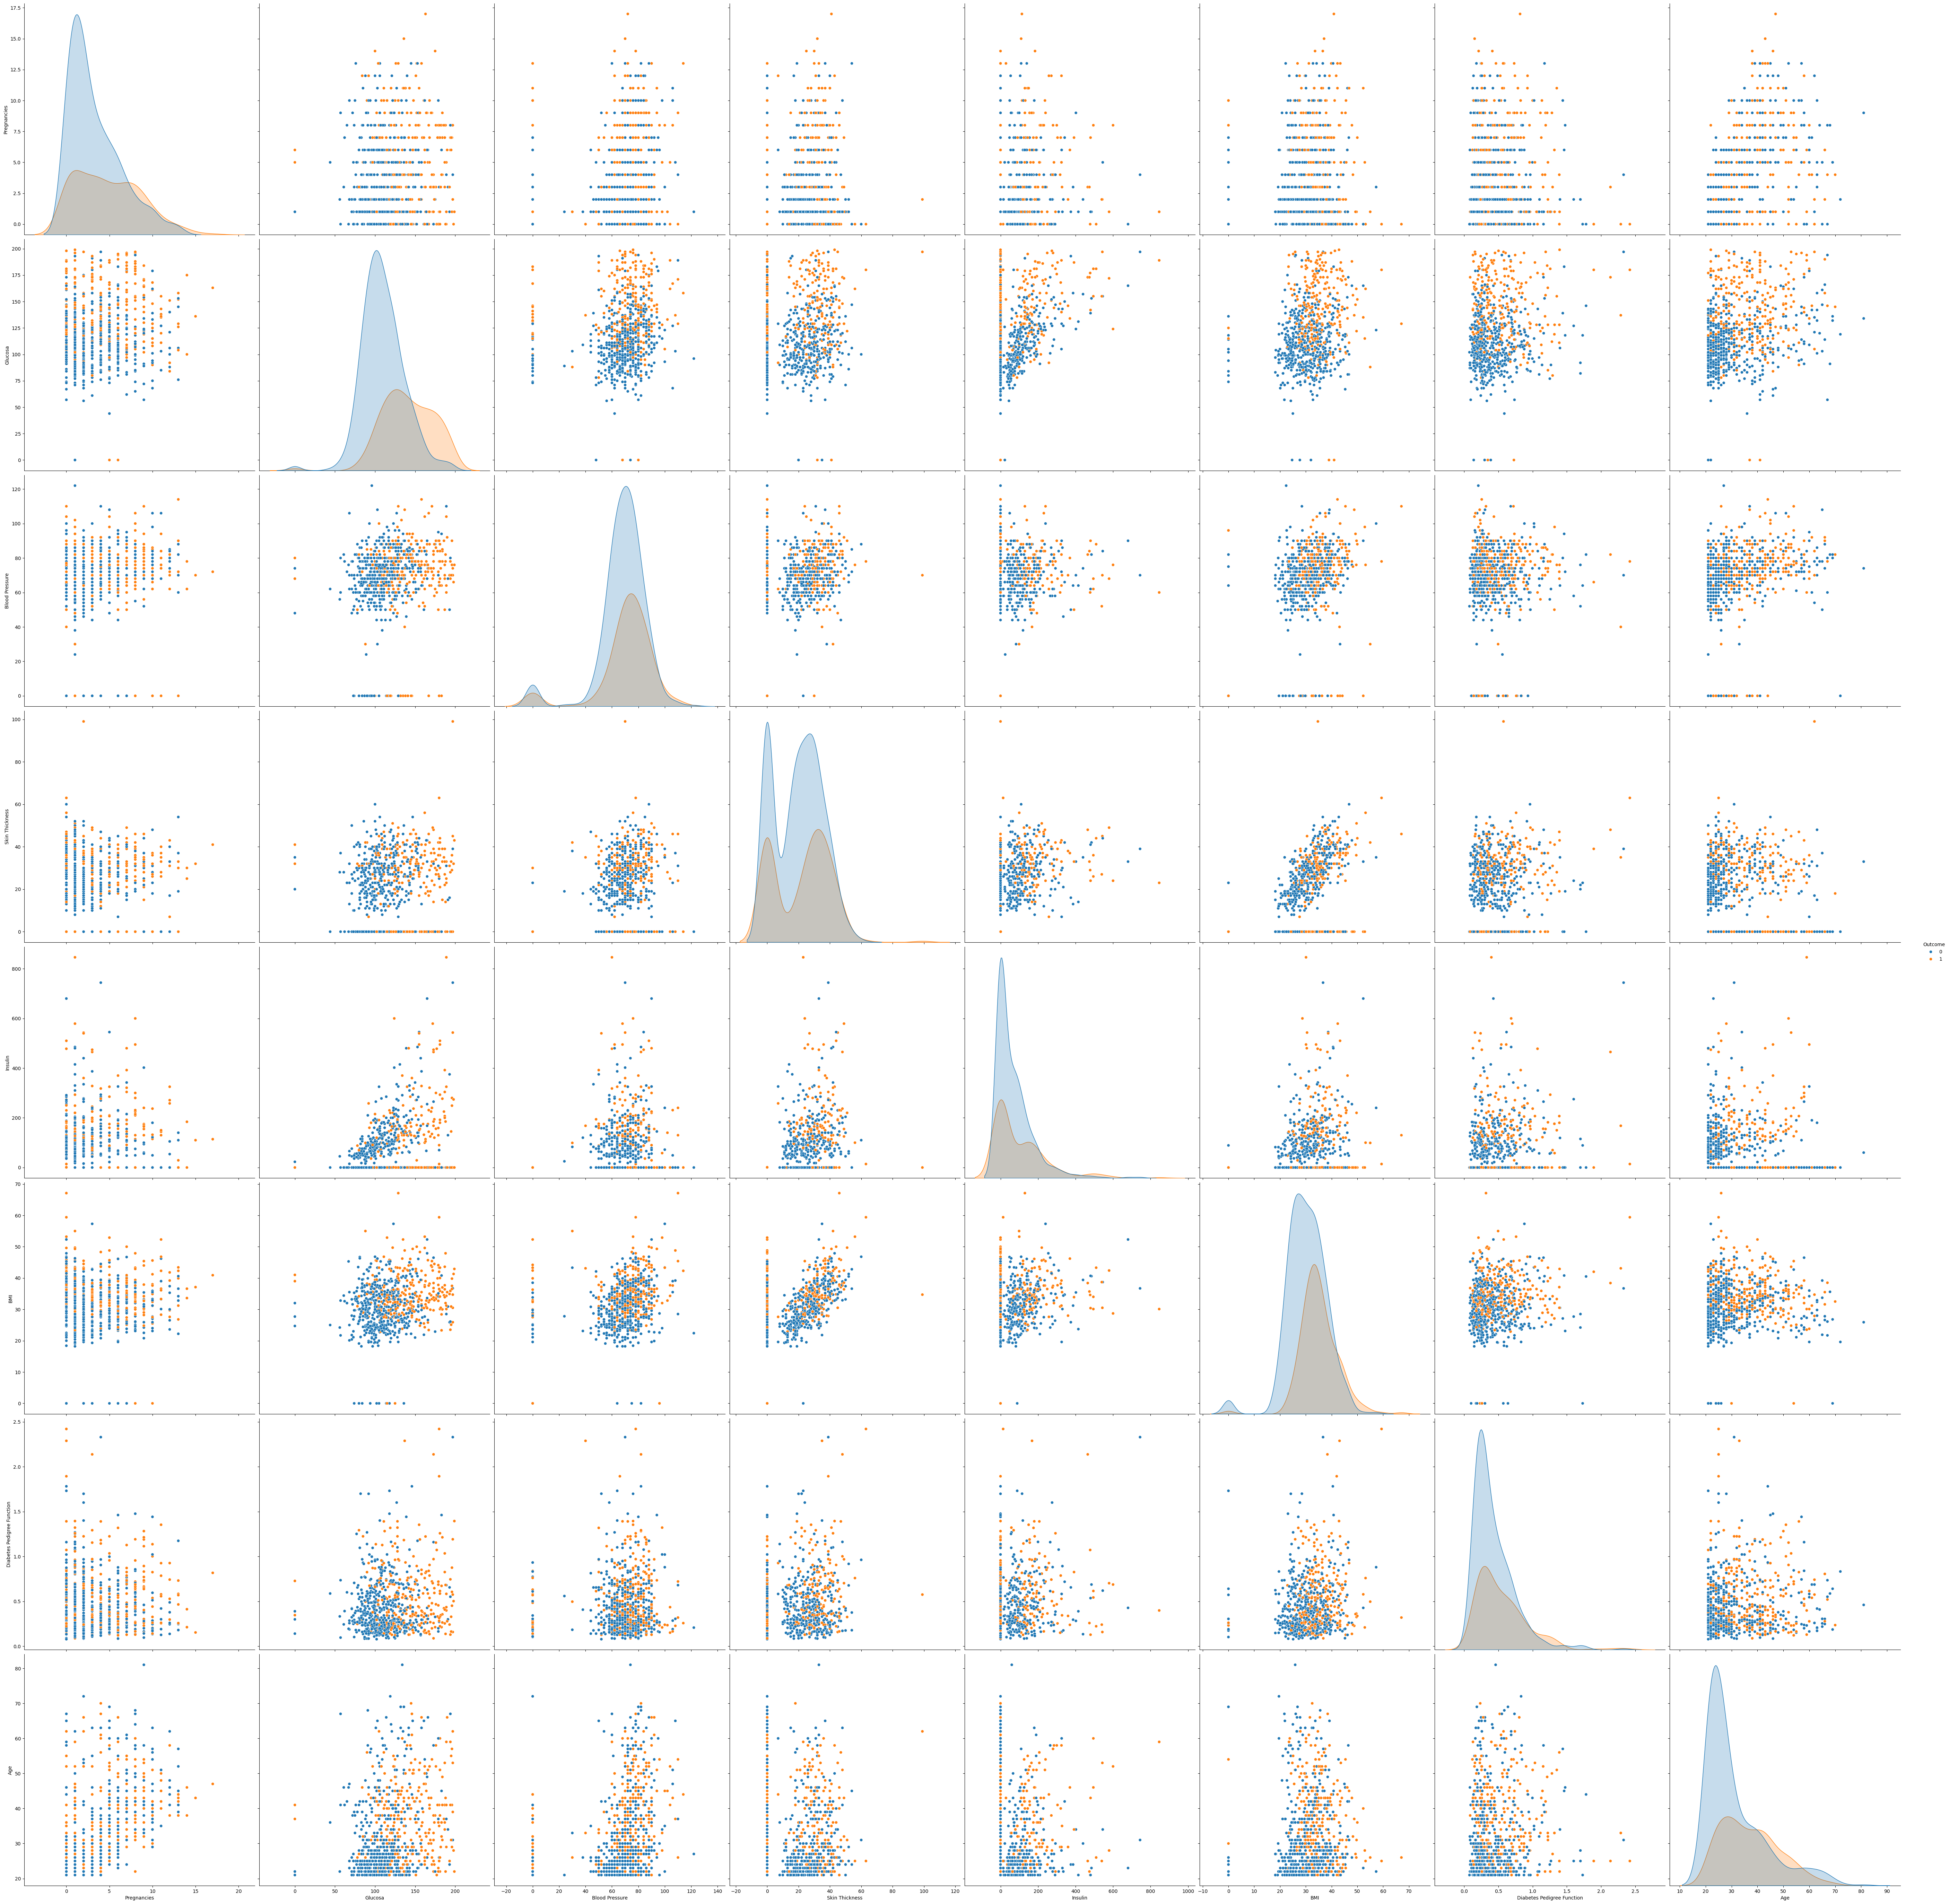

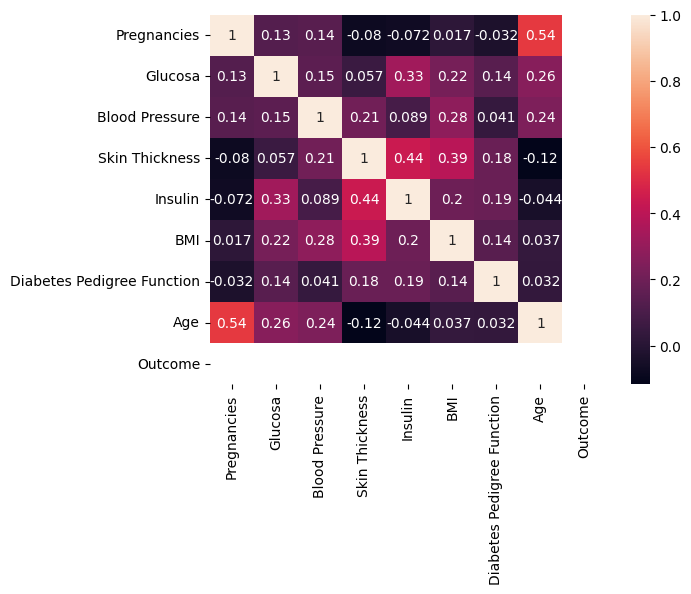

In [ ]:
# Para mirar correlaciones y variables importantes (son cuatro porque son las variables trabajadas)
plt.figure()
sns.pairplot(XDB, hue='Outcome', size=7, vars=['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age'])
plt.show()

# ¿Y cuáles son las correlaciones?
plt.figure()
# Codificar la variable 'Outcome' numéricamente
XDB_encoded = XDB.copy()
XDB_encoded['Outcome'] = XDB_encoded['Outcome'].map({'SD': 0, 'CD': 1})

# Calcular la matriz de correlación con la columna 'Outcome' codificada
sns.heatmap(XDB_encoded.corr(), annot=True)
plt.show()

2. Implementación del modelo

In [ ]:
#Se procede con la implementación del modelo.
from sklearn.cluster import KMeans # Importar KMeans
XD=XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']]
yd=XDB[['Outcome']]

#Se van a crear cinco montoncitos de datos (perfiles de crédito)
np.random.seed(42)
nc=5
mkm=KMeans(n_clusters=nc, random_state=42) #Son números aleatorios
mkm.fit(XD, yd)
centroids=mkm.cluster_centers_
print('Los centroides son:\n', centroids)

Los centroides son:
 [[2.63841808e+00 1.01954802e+02 6.88418079e+01 2.68531073e+01
  7.78418079e+01 3.10966102e+01 4.69457627e-01 2.78361582e+01]
 [4.25000000e+00 1.49615385e+02 7.40384615e+01 3.08653846e+01
  2.91480769e+02 3.55750000e+01 5.58634615e-01 3.39038462e+01]
 [4.39220779e+00 1.19106494e+02 6.73974026e+01 1.19012987e+01
  5.63636364e-01 3.09680519e+01 4.21758442e-01 3.56337662e+01]
 [3.78102190e+00 1.33598540e+02 7.18613139e+01 3.05839416e+01
  1.62452555e+02 3.40481752e+01 5.56503650e-01 3.32335766e+01]
 [3.11111111e+00 1.65833333e+02 7.34444444e+01 3.56666667e+01
  5.48833333e+02 3.69611111e+01 6.60666667e-01 3.45555556e+01]]


In [ ]:
# Cómo quedaron clasificadas las personas
labels = mkm.labels_
XDB['labels'] = labels  # Adiciona a la tabla el cluster al que pertenece el solicitante

# Caracterizamos los centroides
ND = np.bincount(labels)
print('El tamaño de los clusters es: \n', ND)

# Contar el número de registros por cluster y por Outcome
conteo_por_cluster_outcome = XDB.groupby(['labels', 'Outcome']).size().unstack(fill_value=0)
print("Conteo de registros por cluster y Outcome:")
print(conteo_por_cluster_outcome)

# Calcular el número de registros con diagnóstico de diabetes (1) por cluster
num_diabetes_por_cluster = conteo_por_cluster_outcome[1]
print("\nEl número de registros con diagnóstico de diabetes (1) es: \n", num_diabetes_por_cluster)

# Calcular el número de registros sin diagnóstico de diabetes (0) por cluster
num_sindiabetes_por_cluster = conteo_por_cluster_outcome[0]
print("\nEl número de registros sin diagnóstico de diabetes (0) es: \n", num_sindiabetes_por_cluster)

# Calcular el porcentaje de registros con diagnóstico de diabetes (1) por cluster
porcentaje_diabetes_por_cluster = (num_diabetes_por_cluster / ND) * 100
print("\nEl porcentaje de registros con diagnóstico de diabetes (1) por cluster es: \n", porcentaje_diabetes_por_cluster)

# Calcular el porcentaje de registros sin diagnóstico de diabetes (0) por cluster
porcentaje_sindiabetes_por_cluster = (num_sindiabetes_por_cluster / ND) * 100
print("\nEl porcentaje de registros sin diagnóstico de diabetes (0) por cluster es: \n", porcentaje_sindiabetes_por_cluster)

El tamaño de los clusters es: 
 [177  52 385 137  18]
Conteo de registros por cluster y Outcome:
Outcome    0    1
labels           
0        154   23
1         26   26
2        244  141
3         70   67
4          6   12

El número de registros con diagnóstico de diabetes (1) es: 
 labels
0     23
1     26
2    141
3     67
4     12
Name: 1, dtype: int64

El número de registros sin diagnóstico de diabetes (0) es: 
 labels
0    154
1     26
2    244
3     70
4      6
Name: 0, dtype: int64

El porcentaje de registros con diagnóstico de diabetes (1) por cluster es: 
 labels
0    12.994350
1    50.000000
2    36.623377
3    48.905109
4    66.666667
Name: 1, dtype: float64

El porcentaje de registros sin diagnóstico de diabetes (0) por cluster es: 
 labels
0    87.005650
1    50.000000
2    63.376623
3    51.094891
4    33.333333
Name: 0, dtype: float64


In [ ]:
ydp = np.zeros((len(XD), 1))
Vapr = np.array(porcentaje_diabetes_por_cluster)  # El porcentaje de registros con diagnóstico de diabetes (1)
Vneg = np.array(porcentaje_sindiabetes_por_cluster) # El porcentaje de registros sin diagnóstico de diabetes (0)

for k in range(len(XD)):
    napr = labels[k]

    #print("La persona tal:", k)
    #print("El cluster al que pertenece es:", napr)
    #print("El porcentaje de registros con diagnóstico de diabetes (CD) es:", Vapr[napr])
    #print("El porcentaje de registros sin diagnóstico de diabetes (SD) es:", Vneg[napr])

    # Consolidamos la información de los diagnósticos
    if Vapr[napr] > Vneg[napr]:
        ydp[k] = 1  # Asignamos 1 si hay mayor porcentaje de 'CD'
    else:
        ydp[k] = 0  # Asignamos 0 si hay mayor porcentaje de 'SD'

3. Se evalua el modelo

In [ ]:
#Se evalúa el modelo
from sklearn.metrics import confusion_matrix
import numpy as np # Importamos numpy
import pandas as pd # Importamos pandas

# Asegurarse de que yd sea la columna 'Outcome' del DataFrame XDB con valores numéricos (0 y 1)
# Esto evita mezclas si yd fue modificado en celdas anteriores.
yd = XDB['Outcome']

# ydp ya contiene las predicciones numéricas (0 o 1) based on cluster analysis.
# Convertir ydp a un formato compatible with yd (e.g., a numpy array or pandas Series)
# Since yd is a pandas Series, let's convert ydp to a pandas Series for consistency.
ydp_series = pd.Series(ydp.flatten(), name='Predicted Outcome')

# Ahora, yd (pandas Series with 0 and 1) and ydp_series (pandas Series with 0 and 1)
# are compatible for confusion_matrix.

# The confusion matrix expects the same set of labels in y_true and y_pred.
# Let's explicitly define the labels we expect (0 and 1).
labels_for_cm = [0, 1]

cm = confusion_matrix(yd, ydp_series, labels=labels_for_cm)
print("La matriz de confusión es: \n", cm)

VN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
VP = cm[1, 1]

# Métricas de desempeño
Exactitud = (VP + VN) / (VP + VN + FP + FN)
Sensibilidad = VP / (VP + FN)
Especificidad = VN / (VN + FP)
# Corregir el cálculo de Precision para evitar división por cero si VP + FP es cero
Precision = VP / (VP + FP + np.finfo(float).eps) # Use epsilon from numpy

TasaError = (FP + FN) / (VP + VN + FP + FN)

# Corregir el cálculo de PredNeg para evitar división por cero si VN + FN es cero
PredNeg = VN / (VN + FN + np.finfo(float).eps) # Use epsilon from numpy


print("La exactitud es:", Exactitud)
print("La sensibilidad es:", Sensibilidad)
print("La especificidad es:", Especificidad)
print("La precisión es:", Precision)
print("La tasa de error es:", TasaError)
print("La tasa de predicción negativa es:", PredNeg)

La matriz de confusión es: 
 [[494   6]
 [257  12]]
La exactitud es: 0.657997399219766
La sensibilidad es: 0.04460966542750929
La especificidad es: 0.988
La precisión es: 0.6666666666666666
La tasa de error es: 0.3420026007802341
La tasa de predicción negativa es: 0.6577896138482024


# **Modelo Arbol de Decisión**

In [ ]:
import numpy as np
import pandas as pd

#librerías arbol
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

#Conectar al drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Se procede con la carga de datos

In [ ]:
nxl='/content/Diabetes Base de Datos.xlsx'
XDB=pd.read_excel(nxl, sheet_name=0) #Base de datos triple A
XDB=XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age','Outcome']]
display(XDB)

#Separamos las variables por entrada y salida
XD=np.array(XDB[['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']])
yd=np.array(XDB[['Outcome']])

,Pregnancies,Glucosa,Blood Pressure,Skin Thickness,Insulin,BMI,Diabetes Pedigree Function,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
# Contar el número de personas con diabetes (Outcome == 1)
num_diabetes = XDB[XDB['Outcome'] == 1].shape[0]

# Contar el número de personas sin diabetes (Outcome == 0)
num_sindiabetes = XDB[XDB['Outcome'] == 0].shape[0]

print(f"Número de diagnósticos con diabetes (1): {num_diabetes}")
print(f"Número de diagnósticos sin diabetes (0): {num_sindiabetes}")

Número de diagnósticos con diabetes (1): 269
Número de diagnósticos sin diabetes (0): 500


Se realiza la implementación del modelo

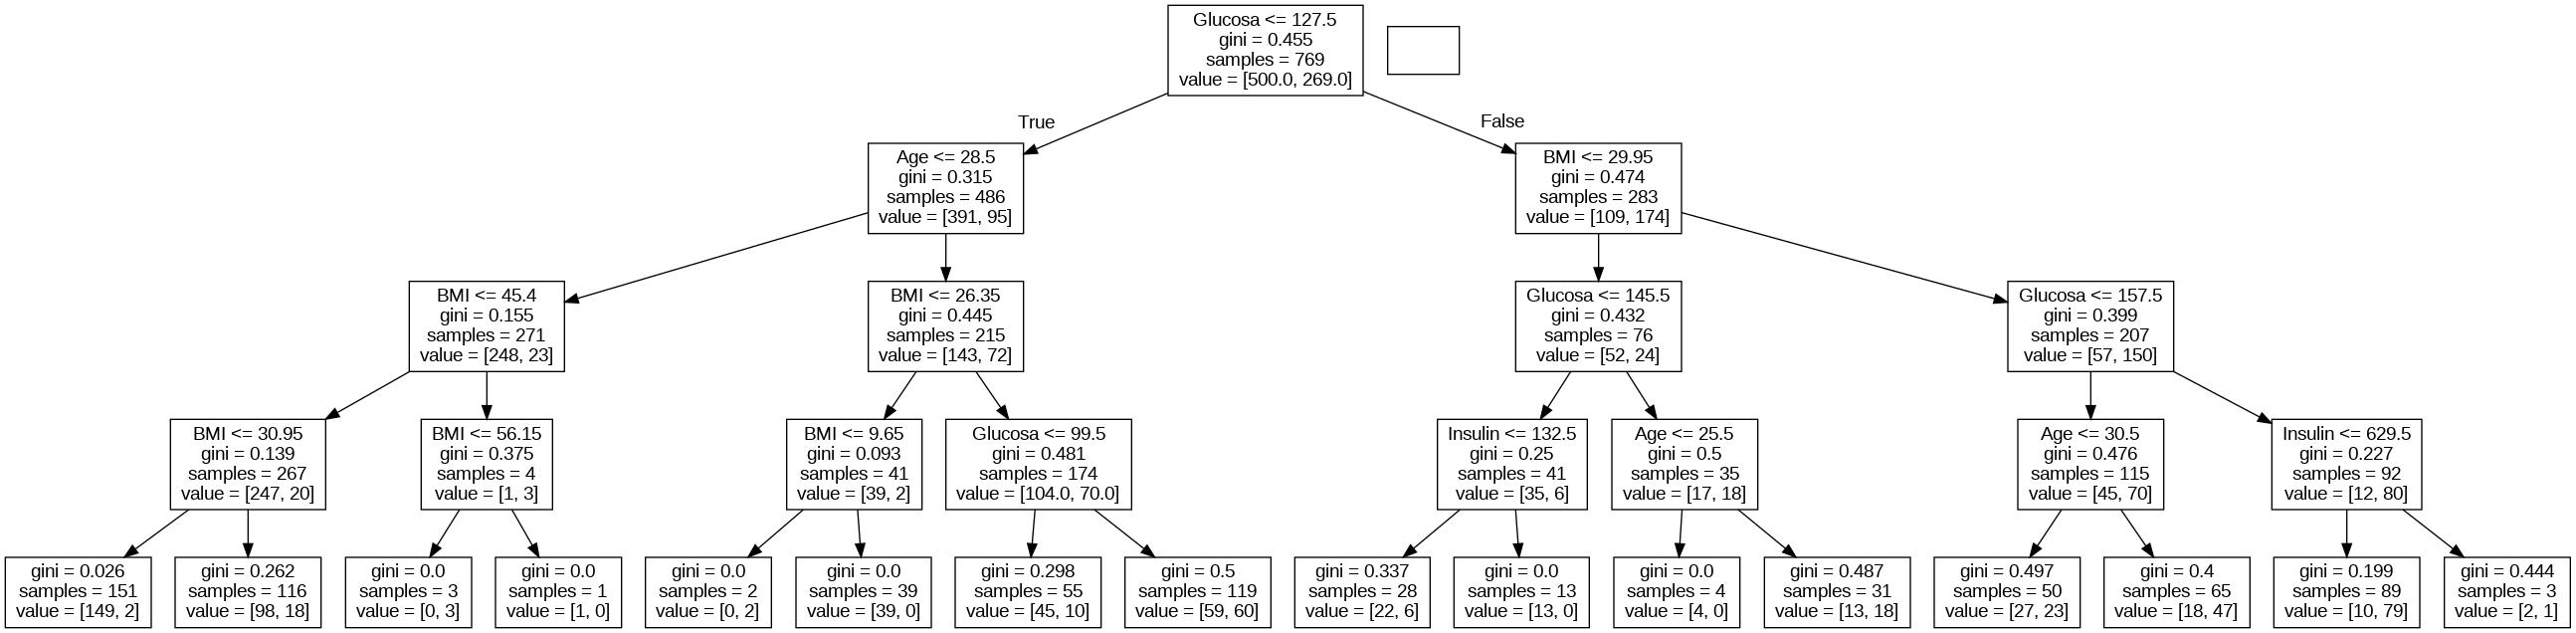

In [ ]:
#Se procede con la gráfica
from pydotplus import graph_from_dot_data #Crea la gráfica
from sklearn.tree import export_graphviz #Lo exporta a PNG, JPEG, TIFF
from IPython.display import Image, display # Importar Image y display

mar=DecisionTreeClassifier(criterion='gini', max_depth=4)
mar.fit(XD,yd)

ve=['Pregnancies', 'Glucosa', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Diabetes Pedigree Function','Age']
dot_data=export_graphviz(mar, feature_names=ve) #Crear el gráfico
graph=graph_from_dot_data(dot_data)
graph.write_png('2. ArbolDecision.png')

# Mostrar la imagen en Colab
display(Image(filename='2. ArbolDecision.png'))

2. S determina el numero de nodos puros

In [ ]:
# Considerar la estructura del árbol
tree = mar.tree_

# Conteo de los nodos puros
pure_nodes_count = 0

for node_id in range(tree.node_count):
    # Comprueba si el nodo es un nodo hoja, es decir, un nodo que no tiene hijos y representa una decisión final o una predicción.
    if tree.children_left[node_id] == tree.children_right[node_id]:
        # Comprueba si es un nodo puro(all samples belong to the same class)
        if tree.impurity[node_id] == 0:
            pure_nodes_count += 1

# Print the number of pure nodes
print("Number of pure nodes:", pure_nodes_count)

Number of pure nodes: 6


3. Evaluar comportamiento del modelo

In [ ]:
ydp=mar.predict(XD) #Pronóstico sobre la base de datos original
cm=confusion_matrix(yd, ydp)
print("La matriz de confusión es: \n", cm)

VN=cm[0,0]; FP=cm[0,1];FN=cm[1,0]; VP=cm[1,1]

Exactitud=(VP+VN)/(VP+VN+FP+FN)
Sensibilidad=VP/(VP+FN)
Especificidad=VN/(VN+FP)
Precision=VP/(VP+FP)
TasaError=(FP+FN)/(VP+VN+FP+FN)
PredNeg=VN/(VN+FN)

print("La exactitud es: ", Exactitud)
print("La sensibilidad es: ", Sensibilidad)
print("La especificidad es: ", Especificidad)
print("La precision es: ", Precision)
print("La tasa de error es: ", TasaError)
print("La presición negativa es:", PredNeg)

La matriz de confusión es: 
 [[400 100]
 [ 60 209]]
La exactitud es:  0.7919375812743823
La sensibilidad es:  0.7769516728624535
La especificidad es:  0.8
La precision es:  0.6763754045307443
La tasa de error es:  0.20806241872561768
La presición negativa es: 0.8695652173913043


# **Análisis de Resultados**

Luego de aplicar y analizar los resultados obtenidos por los modelos de Árbol de Decisión, Naive Bayes y K-Means, se puede concluir que el modelo más adecuado para diagnosticar diabetes en esta base de datos es el Árbol de Decisión. Este modelo presentó la mayor exactitud general (79.2 %), una alta sensibilidad (77.6 %), y una especificidad del 80 %, lo cual indica que logra identificar correctamente tanto a pacientes con como sin diabetes, siendo especialmente útil para evitar falsos negativos, lo que es esencial en el ámbito médico.
Además, este modelo se caracteriza por su capacidad interpretativa, ya que genera reglas claras de clasificación, como por ejemplo condiciones basadas en el índice de masa corporal (BMI), edad y niveles de glucosa. Estas reglas son comprensibles y pueden ser fácilmente explicadas a profesionales de la salud para apoyar la toma de decisiones clínicas.
Por otro lado, el modelo de Naive Bayes obtuvo una exactitud de 76.3 %, con una sensibilidad más baja (61.7 %), aunque presentó una especificidad superior (84.2 %). Esto significa que, si bien clasifica bien a los pacientes sin diabetes, es menos eficaz al detectar casos positivos. No obstante, su simplicidad, velocidad de entrenamiento y resultados aceptables lo hacen una buena opción secundaria, sobre todo en sistemas donde se requiera procesamiento rápido.
En contraste, el modelo de K-Means, al ser un algoritmo no supervisado, presentó limitaciones significativas para este problema de clasificación. Aunque alcanzó una especificidad muy alta (98.8 %), su sensibilidad fue extremadamente baja (4.4 %), lo cual implica que no logra identificar a los pacientes con diabetes. Su exactitud general fue del 65.8 %, la menor entre los modelos evaluados, lo que lo descarta como opción viable para esta tarea en particular.
En conclusión, el Árbol de Decisión es el modelo más robusto y equilibrado para este caso, ya que ofrece un desempeño consistente en todas las métricas relevantes. Su aplicación puede servir como una herramienta útil y confiable en sistemas de apoyo al diagnóstico médico, especialmente en la detección temprana de diabetes, donde minimizar errores es crucial.
